# 2. Optimality, and an algorithm that tries everything

*Part 2 of a series on non-negative least squares (NNLS). Previous:
[1. The geometry of least squares](01_least_squares_geometry.ipynb). Next:
[3. The active-set method](03_active_set_lawson_hanson.ipynb).*

Notebook 1 ended on an observation. The NNLS answer always switches some of the references on
and the rest off, and on the ones it switches on, it's just the ordinary least-squares fit.
That suggests an algorithm that sounds almost too lazy to work: **try every possible subset of
references, fit each by least squares, throw away the fits with a negative weight, and keep
the best of what's left.**

This notebook proves that the lazy algorithm is exactly right. Along the way it builds a second
way of looking at the problem, one that the rest of the series leans on:

1. **Weight space.** Instead of drawing spectra, draw the *weights*. The error
   $f(w) = \|Rw - s\|^2$ becomes a bowl, and the constraint $w \ge 0$ becomes a fence.
2. **The gradient**, which tells you which way is downhill. You'll need only the idea of a
   derivative from first-year calculus.
3. **Optimality conditions.** At the bottom of a fenced bowl, no direction is both downhill
   and allowed. Written out, these are the famous *KKT conditions*, and they turn out to be
   notebook 1's Theorem 5 in disguise.
4. **The proof** that trying every subset works, including what to do with subsets whose
   columns are linearly dependent.
5. **A shortcut** that squeezes the whole problem down to a few small numbers, so that each
   subset costs almost nothing to try.

Theorems are numbered on from notebook 1, which ended at Theorem 5, so a theorem number always
means one thing across the series. As in notebook 1, each figure with a widget is first shown
as fixed snapshots, so it reads without a running kernel.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import scipy.optimize

from nnls_tutorial import plotting as P
from nnls_tutorial import weight_space as W
from nnls_tutorial.data import load_arsenic
from nnls_tutorial.solvers import (
    candidates,
    gradient,
    nnls_enumerate,
    normal_equations,
    support_fit,
    supports,
)

P.use_style()
np.set_printoptions(precision=4, suppress=True)

spectra = load_arsenic()
TEASER = ["Arsenopyrite_Julcani_OA", "As_pyrite_A_Foster_sln", "Lollingite_Lolling_avg_OA"]
BEST_FIT = [
    "Arsenopyrite_Julcani_OA",
    "orpiment_all_ref_als_cal",
    "arsenate_sorbed_diop_avg_als_cal",
]
teaser_columns = [spectra.names.index(name) for name in TEASER]
R, s = spectra.R[:, teaser_columns], spectra.s

## 1. From spectrum space to weight space

Every picture in notebook 1 lived in *spectrum space*, the space where $s$ and the columns
$r_i$ live, with axes $f_1, f_2, \dots$ for the fluorescence at each energy. There, NNLS was
about the point of a cone closest to $s$.

Now flip the point of view. Each choice of weights $w = (w_1, \dots, w_m)$ is a point of
**weight space** $\mathbb{R}^m$, and each one gets a score, its error

$$f(w) = \|Rw - s\|^2.$$

With two references, weight space is a plane, and $f$ is a surface over it. NNLS asks for the
lowest point of that surface among the weights with $w_1 \ge 0$ and $w_2 \ge 0$, a quarter of
the plane. Figure 2.1 shows both views of the same two-column problem, using the positions of
$s$ from Figure 1.5.

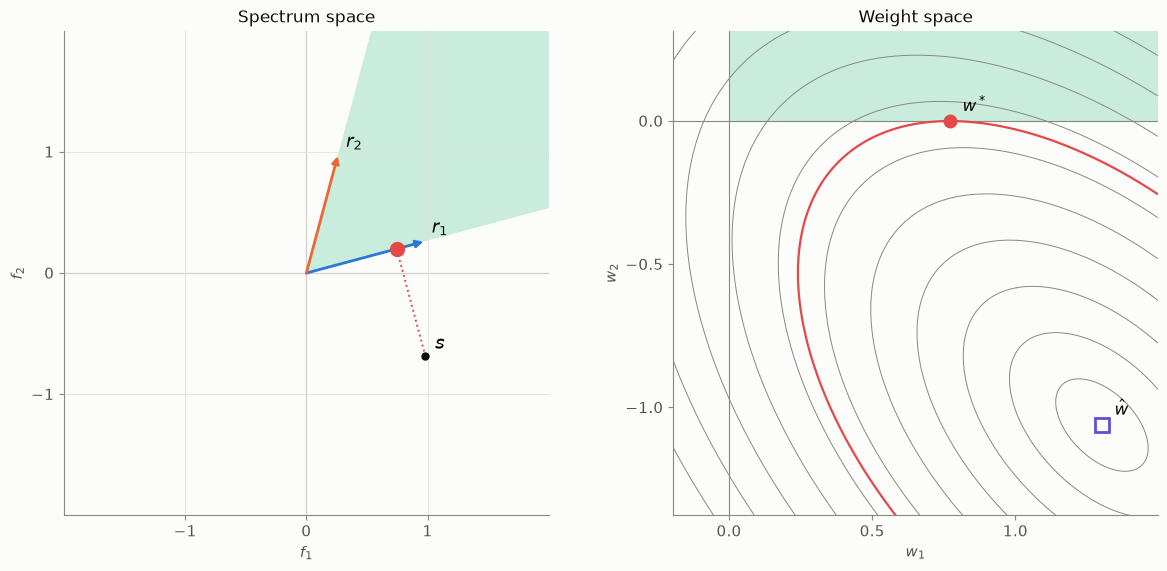

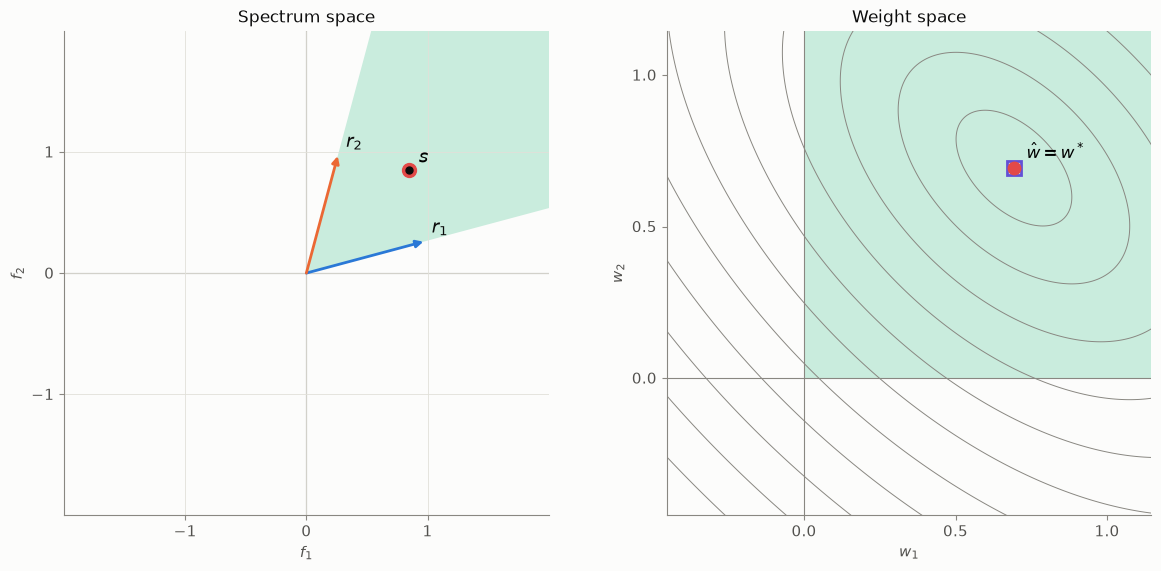

In [2]:
W.two_spaces_static()

**Figure 2.1.** One problem seen two ways, for two positions of $s$. Left: spectrum space, as
in notebook 1, with the cone shaded and $q = Rw^*$, the closest point of the cone to $s$, in
red. Right: weight space. The gray curves are contours of $f$, curves along which the error
is constant. The shaded quarter is the allowed region $w \ge 0$, in the same color as the cone,
because $R$ maps the one onto the other. The hollow square $\hat w$ is the least-squares
answer, at the bottom of the bowl, and the red dot $w^*$ is the NNLS answer. The red contour is
the lowest one that touches the allowed region. Top: $s$ is below $r_1$, so the bottom of the
bowl has a negative $w_2$ and NNLS must settle for a point on the edge. Bottom: $s$ is inside
the cone, so the bottom of the bowl is allowed and $\hat w = w^*$.

The contours are ellipses centered on $\hat w$, nested like the rings of a bowl seen from
above. Here's why the bowl's bottom is at $\hat w$, and how fast it rises from there.

> **Theorem 6 (the bowl).** Let $\hat w$ be a least-squares solution. For every $w$,
> $$f(w) = f(\hat w) + \|R(w - \hat w)\|^2.$$

*Proof.* Split the residual as $s - Rw = (s - R\hat w) + R(\hat w - w)$. The first piece is
orthogonal to every column (Theorem 1), so to the second piece too, and Pythagoras gives the
result. $\blacksquare$

So $f$ never drops below $f(\hat w)$, and it rises in every direction you move away from
$\hat w$, at least when the columns are independent, since then $R(w - \hat w) \ne 0$ for
$w \ne \hat w$. The contour where $f = f(\hat w) + k$ is the set of $w$ with
$\|R(w - \hat w)\|^2 = k$. If you know the spectral theorem for symmetric matrices, you can
show that's an ellipse. Notebook 4 does this properly, because the *shape* of those ellipses
turns out to matter a lot for accuracy.

One more remark about Figure 2.1. In these tiny examples two columns span the whole plane, so
least squares fits $s$ exactly and the bowl's bottom is at $f = 0$. That's special to the
example. With real spectra, $f(\hat w) > 0$, but nothing else changes.

## 2. Which way is downhill? The gradient

To talk about the lowest point of a surface, we need to know which way is down. Pick a point
$w$ and a direction $d$, and walk along the line $w + td$. The error along that walk is
a function of the single number $t$, and for our $f$ you can just expand it:

$$f(w + td) = \|(Rw - s) + t\,Rd\|^2 = f(w) + 2t\,(Rd)\cdot(Rw - s) + t^2\|Rd\|^2.$$

Move the $R$ across the dot product, using $(Rd)\cdot v = d \cdot (R^\top v)$, and this
becomes the following.

> **Theorem 7 (the gradient).** Define
> $$\nabla f(w) = 2R^\top(Rw - s) = -2R^\top e, \qquad\text{where } e = s - Rw.$$
> Then for every point $w$, direction $d$ and number $t$,
> $$f(w + td) = f(w) + t\,\nabla f(w)\cdot d + t^2\|Rd\|^2.$$

The vector $\nabla f(w)$ is called the **gradient** of $f$ at $w$. Its $i$-th entry is the
partial derivative $\partial f / \partial w_i$, the rate at which $f$ changes when you nudge
only $w_i$. (Take $d$ to be the $i$-th standard basis vector and look at the coefficient of
$t$.) Three things to take from Theorem 7:

- **The slope in direction $d$ is $\nabla f(w) \cdot d$.** That's the derivative of
  $f(w + td)$ at $t = 0$, read off from the coefficient of $t$. If it's negative, a small step
  in direction $d$ goes downhill.
- **The gradient points uphill, steepest.** Among directions of length 1, the dot product
  $\nabla f \cdot d$ is largest when $d$ points along $\nabla f$ (Cauchy–Schwarz). So
  $-\nabla f$ is the steepest way down, and the gradient is perpendicular to the contours, since
  along a contour $f$ doesn't change at all.
- **There's no error term.** For a general function, the expansion would only hold
  approximately for small $t$. Ours is a quadratic, so it's exact for every $t$. Every proof
  in this notebook uses that.

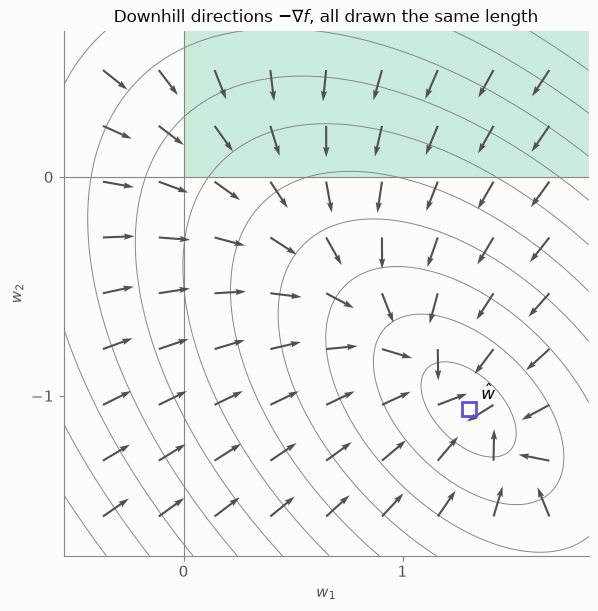

In [3]:
P.show(W.gradient_figure())

**Figure 2.2.** The downhill direction $-\nabla f$ at points all over weight space, for the
problem in the top row of Figure 2.1. Every arrow is drawn the same length, so only the
direction shows. The arrows cross the contours at right angles and point toward the bottom of
the bowl at $\hat w$, but not *straight* at it: on a stretched bowl, steepest descent swerves.
That's why "keep walking downhill" can be a slow algorithm, and why notebook 3 does something
smarter.

Notice the gradient's formula: $\nabla f(w) = -2R^\top e$. Its entries are the dot products
$e\cdot r_i$ of the residual with each column, which are exactly the numbers in notebook 1's
Theorem 5, times $-2$. Hold that thought.

## 3. The bottom of a fenced bowl

Without the fence, the lowest point of the bowl is where the gradient is zero:
$\nabla f(\hat w) = 0$ is the same equation as the normal equations $R^\top R\hat w = R^\top s$.
With the fence $w \ge 0$, the lowest *allowed* point may sit against the fence, where the
ground still slopes down, just not in any direction the fence allows. Here's the precise
statement. Write $Q = \{w : w \ge 0\}$ for the allowed region, the quadrant in our pictures.

> **Theorem 8 (no allowed way down).** A point $w^* \in Q$ minimizes $f$ over $Q$ if and only
> if
> $$\nabla f(w^*) \cdot (w - w^*) \ge 0 \quad\text{for every } w \in Q.$$
> In words: every direction that stays inside $Q$ goes uphill, or at least not down.

*Proof.* Fix $w \in Q$, let $d = w - w^*$, and use Theorem 7 for $0 \le t \le 1$:

$$f(w^* + td) = f(w^*) + t\,\nabla f(w^*)\cdot d + t^2\|Rd\|^2.$$

($\Leftarrow$) If $\nabla f(w^*) \cdot d \ge 0$, every term after $f(w^*)$ is $\ge 0$, so at
$t = 1$, $f(w) \ge f(w^*)$.

($\Rightarrow$) If $\nabla f(w^*) \cdot d < 0$ for some $w \in Q$, then for small $t > 0$ the
negative middle term beats the $t^2$ term, so $f(w^* + td) < f(w^*)$. And $w^* + td$ is in $Q$,
because it's an average of $w^*$ and $w$, and averages of non-negative vectors are
non-negative. So $w^*$ wasn't the minimizer. $\blacksquare$

If this feels familiar, it should. It's the obtuse-angle test of notebook 1 (Theorem 3), redone
in weight space with the gradient in place of $s - q$. The reason it works is the same in both:
$f$ is **convex**. Along any line, $f$ is a parabola $f(w) + bt + t^2\|Rd\|^2$ that opens
upward (or is flat), so it can't have a dip that isn't its lowest point.

### The KKT conditions

Theorem 8 has to be checked against every $w \in Q$, which sounds like infinitely much work.
For the quadrant it boils down to a handful of sign checks, one per weight. Write
$\lambda = \nabla f(w^*)$ for the gradient at the candidate answer.

> **Theorem 9 (KKT conditions for NNLS).** $w^* \ge 0$ solves NNLS if and only if
> $\lambda = \nabla f(w^*)$ satisfies, for every $i$,
> $$\lambda_i \ge 0 \qquad\text{and}\qquad \lambda_i w^*_i = 0.$$

*Proof.* ($\Rightarrow$) Apply Theorem 8 to three cheap points of $Q$. With $w = w^* + $ (the
$i$-th basis vector), it says $\lambda_i \ge 0$. With $w = 0$ and with $w = 2w^*$, it says
$\lambda \cdot w^* \le 0$ and $\lambda \cdot w^* \ge 0$, so $\lambda \cdot w^* = 0$. That's a
sum of terms $\lambda_i w^*_i$, each $\ge 0$, adding to zero, so every term is zero.

($\Leftarrow$) For any $w \in Q$,
$\lambda \cdot (w - w^*) = \sum_i \lambda_i w_i - \sum_i \lambda_i w^*_i = \sum_i \lambda_i w_i - 0 \ge 0$,
which is Theorem 8's condition. $\blacksquare$

The condition $\lambda_i w^*_i = 0$ says that **for each weight, either the weight is zero or
its slope is** (or both). A weight that's switched on sits at the bottom of the bowl in its
own direction. A weight that's switched off is held at zero by the fence, and $\lambda_i \ge 0$
says the ground there slopes *up* into the allowed region: pushing that weight above zero
would make things worse.

These are the **Karush–Kuhn–Tucker (KKT) conditions**, named for the people who found them,
William Karush in 1939 and Harold Kuhn and Albert Tucker in 1951. They're the standard
optimality conditions for any optimization problem with inequality constraints, and $\lambda$
is called the vector of **multipliers**. For general problems they're only necessary.
Convexity is what makes them sufficient too.

Since $\lambda = -2R^\top e$, the condition $\lambda_i \ge 0$ is $e\cdot r_i \le 0$, and
$\lambda_i = 0$ is $e \cdot r_i = 0$. So **Theorem 9 is notebook 1's Theorem 5, word for
word**, reached by calculus in weight space instead of geometry in spectrum space. Figure 2.3
shows the three kinds of answer it allows.

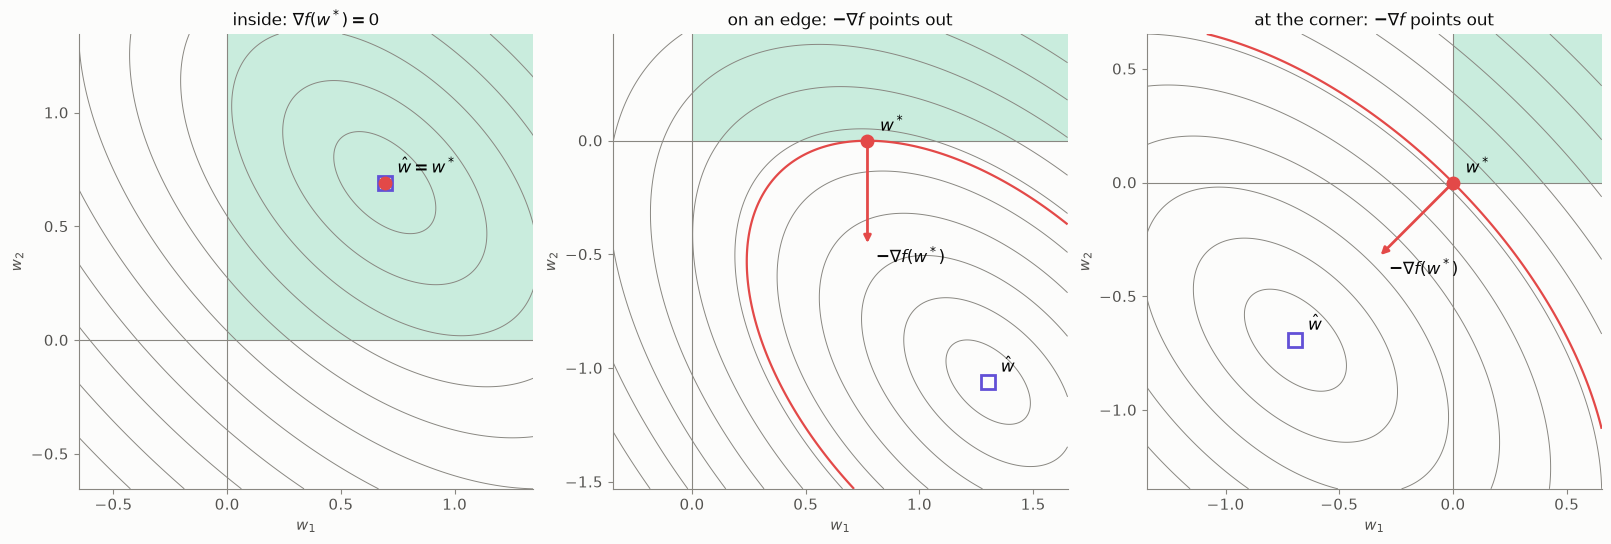

In [4]:
P.show(W.kkt_figure())

**Figure 2.3.** The KKT conditions in the three cases, using the positions of $s$ from Figure
1.5. Left: $w^*$ is inside the allowed region, so both weights are on, both slopes are zero,
and $w^* = \hat w$ is the bottom of the bowl. Middle: $w^*$ is on the edge $w_2 = 0$. Its slope
along the edge is zero ($\lambda_1 = 0$), and the downhill direction $-\nabla f$ points straight
out through the fence ($\lambda_2 > 0$). Right: $w^*$ is the corner $w = 0$, and the downhill
direction points out of the quadrant entirely ($\lambda_1, \lambda_2 > 0$).

Here's the check on the real spectra from Figure 1.1:

In [5]:
w_star = nnls_enumerate(R, s)
lam = gradient(R, s, w_star)
print("w*     =", w_star)
print("lambda =", lam.round(4) + 0.0)  # + 0.0 turns -0.0 into 0.0
print("lambda_i * w*_i =", (lam * w_star).round(10) + 0.0)

w*     = [0.     0.5685 0.4976]
lambda = [0.5416 0.     0.    ]
lambda_i * w*_i = [0. 0. 0.]


Arsenopyrite is off, and its slope is positive: making it any amount larger than zero would
increase the error. The other two are on, with zero slope. (Compare notebook 1, where
$R^\top e$ came out as $(-0.2708, 0, 0)$: multiply by $-2$.)

## 4. Try every support

The **support** of a weight vector is the set of positions where it's switched on,
$P = \{i : w_i > 0\}$. With $m$ references there are $2^m$ possible supports, including the
empty one. For each support $P$, the **candidate** is the least-squares fit using only the
columns in $P$, with zeros elsewhere. Write $R_P$ for the matrix of those columns.

> **Theorem 10 (trying every support is exact).** Consider the candidates for every support
> whose columns are linearly independent, plus $w = 0$ for the empty support. Discard any
> candidate with a negative weight. The remaining candidate with the smallest error $f$ is an
> NNLS solution.

*Proof.* By Theorem 11 below, NNLS has a solution $w^*$ whose support $P$ has linearly
independent columns. By Theorem 9, $\lambda_i = 0$ for every $i \in P$. Since $w^*$ is zero
outside $P$, the entries of $\lambda$ in $P$ only involve the columns in $P$:

$$0 = \lambda_P = 2R_P^\top(R_P w^*_P - s),$$

which is exactly the normal equations for fitting $s$ with the columns of $R_P$. Those columns
are independent, so the fit is unique (Exercise 1 of notebook 1): $w^*$ *is* the candidate for
$P$. It has no negative weights, so it survives the discarding.

Every other surviving candidate has non-negative weights too, so it's an allowed point, and
its error is at least $f(w^*)$. Therefore the smallest error among the survivors is exactly
$f(w^*)$, and whichever candidate achieves it is an NNLS solution. $\blacksquare$

Notice what the proof did *not* need: any check that $\lambda_i \ge 0$ for the weights that
are off. Comparing errors takes care of that automatically. Exercise 3 shows why the comparison
is needed: a candidate can have no negative weights and still not be optimal.

> **Theorem 11 (dependent supports can be skipped).** NNLS has a solution whose support has
> linearly independent columns.

*Proof.* NNLS has a solution: notebook 1 showed the closest point $q$ of the cone exists, and
any $w \ge 0$ with $Rw = q$ is a solution. Among all solutions, pick one, $w^*$, with as few
non-zero weights as possible. Suppose its support's columns were dependent. Then there's a
$v \ne 0$, zero outside the support, with $Rv = 0$. Flipping its sign if needed, some
$v_i > 0$. Now slide: $w^* - tv$ has $R(w^* - tv) = Rw^*$, so the same error, for every $t$.
Increase $t$ from zero until the first weight reaches zero. That's an allowed solution with
fewer non-zero weights, a contradiction. $\blacksquare$

This is the same sliding argument as the "for the curious" box in notebook 1, applied to a
solution instead of a point of the cone. It matters in practice: two reference spectra can be
almost identical, and a support containing both can be badly behaved. Theorem 11 says the
algorithm never *needs* such a support. Notebook 4 comes back to "almost".

Figure 2.4 shows every candidate for the four positions of $s$ from Figure 1.5.

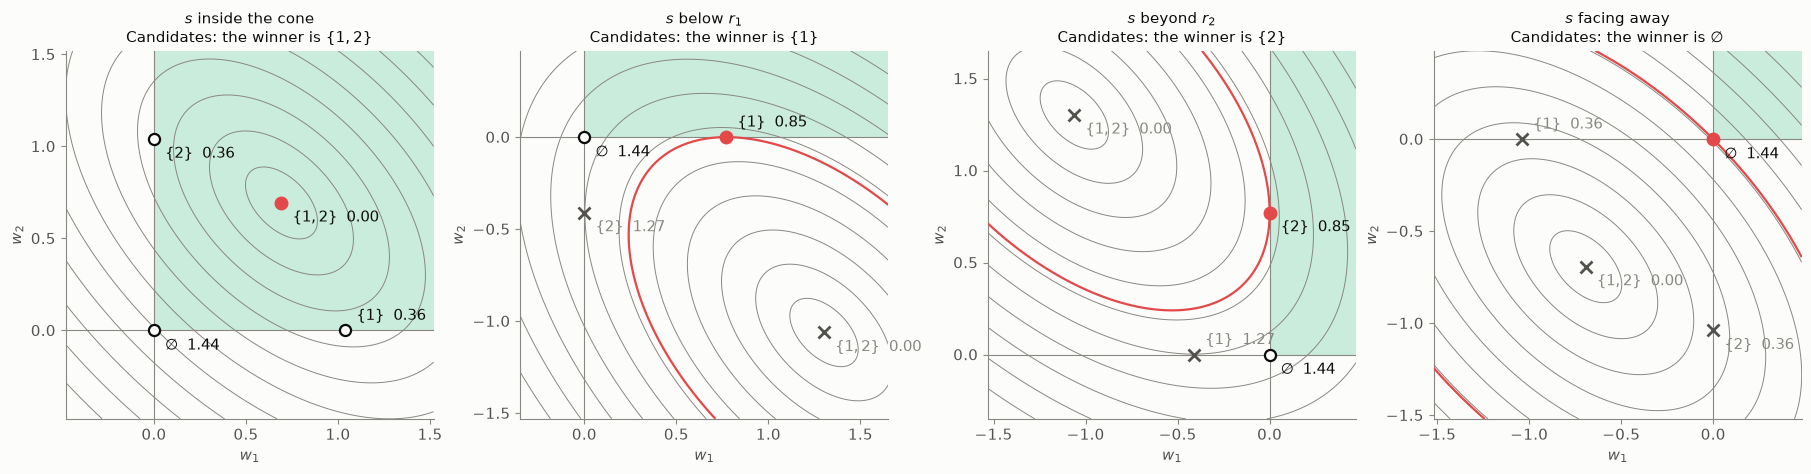

In [6]:
W.candidates_static()

**Figure 2.4.** Every candidate in weight space, for $s$ in each of Figure 1.5's four
regions. Each candidate is labeled with its support and its error $f$. A cross means it has a
negative weight and is discarded; a hollow circle means it's allowed; the red dot is the
winner, the allowed candidate with the smallest error. The empty support's candidate is the
origin, the $\{1\}$ candidate is on the $w_1$ axis (the bowl's lowest point along that axis),
and the $\{1, 2\}$ candidate is the bottom of the bowl. In the first panel all four are
allowed, and the winner is the bowl's bottom. In the others, the bottom has a negative weight,
and the winner is the best of what's left. The widget below also shows spectrum space. There,
each one-column candidate is the closest point to $s$ on the *whole line* through $r_1$ or
$r_2$, and it's discarded exactly when it lands on the backward half of the line, outside the
cone.

In [7]:
W.candidates_widget()

interactive(children=(IntSlider(value=60, continuous_update=False, description='angle between $r_1$ and $r_2$ …

Here are the candidates for the real three-reference problem, all $2^3 = 8$ of them, in
a table and then in Figure 2.5 along with the candidates for MrFitty's best fit:

In [8]:
labels = [spectra.labels[j] for j in teaser_columns]
pd.DataFrame(
    [
        {
            "support": ", ".join(labels[i] for i in cand.support) or "(none)",
            **{label: cand.w[i] for i, label in enumerate(labels)},
            "error f(w)": cand.error,
            "allowed": "yes" if cand.feasible else "no: negative weight",
        }
        for cand in candidates(R, s)
    ]
).round(4)

,support,arsenopyrite,As-pyrite,löllingite,error f(w),allowed
0,(none),0.0000,0.0000,0.0000,181.1079,yes
1,arsenopyrite,1.0268,0.0000,0.0000,1.9480,yes
2,As-pyrite,0.0000,1.1123,0.0000,1.3858,yes
3,löllingite,0.0000,0.0000,1.0090,1.4410,yes
4,"arsenopyrite, As-pyrite",0.3473,0.7384,0.0000,1.1894,yes
5,"arsenopyrite, löllingite",0.3133,0.0000,0.7027,1.3211,yes
6,"As-pyrite, löllingite",0.0000,0.5685,0.4976,0.6420,yes
7,"arsenopyrite, As-pyrite, löllingite",-0.3938,0.7517,0.7179,0.5353,no: negative weight


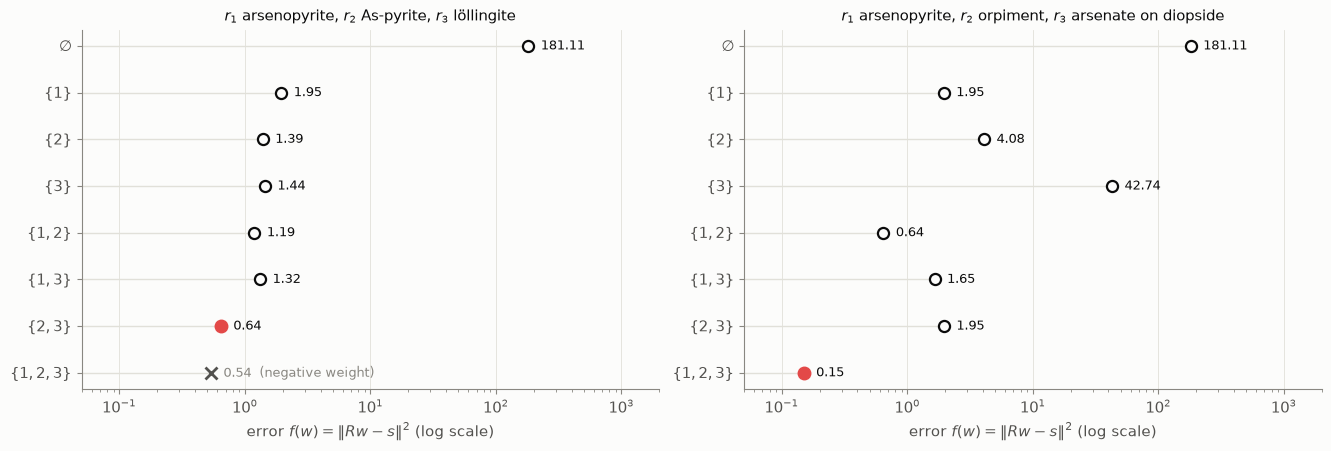

In [9]:
P.show(W.real_candidates_figure(spectra, [TEASER, BEST_FIT]))

**Figure 2.5.** The error of every candidate, on a log scale, for two trios of real
references: the trio from Figure 1.1 (left) and MrFitty's best fit for this sample (right).
Markers as in Figure 2.4. On the left, the full three-reference fit has the smallest error of
all, 0.54, but it needs $-0.39$ of arsenopyrite, so it's discarded, and the winner is
$\{2, 3\}$ at 0.64. On the right, the full fit is allowed, so it wins outright. The empty
support's error is $\|s\|^2$, the same on both sides.

## 5. Squeezing the problem: the error shortcut

Each candidate is a least-squares fit, which means solving the normal equations for its
columns. Written out, those use only the dot products of the columns with each other and with
$s$, which suggests computing all the dot products once, up front:

$$G = R^\top R \;\;(m \times m), \qquad c = R^\top s \;\;(m \text{ numbers}), \qquad s^\top s \;\;(\text{one number}).$$

The entries of $G$ measure how much the references overlap ($G_{ij} = r_i \cdot r_j$), and $c$
measures how much each one lines up with $s$. Expanding $f$ shows these are all it depends on:

$$f(w) = \|Rw - s\|^2 = w^\top G w - 2c^\top w + s^\top s.$$

For a support $P$, write $G_{PP}$ and $c_P$ for the rows and columns of $G$, and entries of $c$,
that belong to $P$. The candidate's weights $z$ solve $G_{PP}\, z = c_P$, a system of at most
$m$ equations. And its error comes almost for free:

> **Theorem 12 (the error shortcut).** If $G_{PP}\, z = c_P$, then
> $$\|R_P z - s\|^2 = s^\top s - z^\top c_P.$$

*Proof.* Expand: $\|R_P z - s\|^2 = z^\top G_{PP} z - 2z^\top c_P + s^\top s$. Replace
$G_{PP}\,z$ by $c_P$ in the first term. $\blacksquare$

This is a bigger deal than it looks. The spectra have 198 energies, but after computing $G$,
$c$ and $s^\top s$ once, **no vector of length 198 is ever touched again**. Every candidate's
weights and error come from a few numbers. Here's that squeezed version of the problem for the
spectra of Figure 1.1:

In [10]:
G, c, ss = normal_equations(R, s)
print("G =\n", G.round(2))
print("c =", c.round(2))
print("s.s =", round(ss, 2))

G =
 [[169.92 156.36 172.54]
 [156.36 145.26 158.74]
 [172.54 158.74 176.47]]
c = [174.48 161.58 178.06]
s.s = 181.11


And here's the whole algorithm, written with them. It's short enough to read in one go:

In [11]:
def nnls_by_enumeration(R, s):
    """NNLS by trying every support (Theorems 10, 11 and 12)."""
    G, c, ss = normal_equations(R, s)
    m = len(c)
    best_w, best_error = np.zeros(m), ss  # the empty support: w = 0, error s.s
    for support in supports(m):
        P = list(support)
        if np.linalg.matrix_rank(G[np.ix_(P, P)]) < len(P):
            continue  # dependent columns: never needed (Theorem 11)
        z, error = support_fit(G, c, ss, support)  # solves G_PP z = c_P (Theorem 12)
        if np.all(z >= 0) and error < best_error:  # allowed, and the best so far (Theorem 10)
            best_w, best_error = np.zeros(m), error
            best_w[P] = z
    return best_w

Ties go to the smaller support, because supports are tried smallest first and a candidate
only replaces the best one if it's strictly better. Let's check it against SciPy's NNLS solver,
on both real trios and on a thousand random problems built so that most of them need some
weights switched off:

In [12]:
for names in [TEASER, BEST_FIT]:
    columns = [spectra.names.index(name) for name in names]
    w_ours = nnls_by_enumeration(spectra.R[:, columns], spectra.s)
    w_scipy, _ = scipy.optimize.nnls(spectra.R[:, columns], spectra.s)
    print(
        f"ours {w_ours}   scipy {w_scipy}   largest difference {np.abs(w_ours - w_scipy).max():.1e}"
    )

rng = np.random.default_rng(0)
worst = 0.0
for _ in range(1000):
    m = int(rng.integers(1, 6))
    R_test = rng.random((30, m))
    s_test = R_test @ rng.normal(size=m) + 0.05 * rng.normal(size=30)
    worst = max(
        worst,
        np.abs(nnls_by_enumeration(R_test, s_test) - scipy.optimize.nnls(R_test, s_test)[0]).max(),
    )
print(f"1000 random problems with 1 to 5 references: largest difference from SciPy {worst:.1e}")

ours [0.     0.5685 0.4976]   scipy [0.     0.5685 0.4976]   largest difference 3.1e-14
ours [0.5197 0.3958 0.0856]   scipy [0.5197 0.3958 0.0856]   largest difference 8.5e-15


1000 random problems with 1 to 5 references: largest difference from SciPy 6.9e-15


The answers agree to 13 digits or better. As a last check, here are the shortcut errors
next to errors computed the long way, from the 198-long residual:

In [13]:
for cand in candidates(R, s)[1:]:
    z, shortcut = support_fit(G, c, ss, cand.support)
    print(
        f"support {str(cand.support):10} long way {cand.error:.6f}   shortcut {shortcut:.6f}"
        f"   difference {abs(cand.error - shortcut):.1e}"
    )

support (0,)       long way 1.948015   shortcut 1.948015   difference 9.3e-14
support (1,)       long way 1.385783   shortcut 1.385783   difference 1.2e-13
support (2,)       long way 1.441014   shortcut 1.441014   difference 1.6e-14
support (0, 1)     long way 1.189444   shortcut 1.189444   difference 9.3e-14
support (0, 2)     long way 1.321053   shortcut 1.321053   difference 5.6e-14
support (1, 2)     long way 0.641977   shortcut 0.641977   difference 2.7e-14
support (0, 1, 2)  long way 0.535335   shortcut 0.535335   difference 1.2e-13


They agree to about 13 digits, not 16. The shortcut subtracts two numbers of size about 181,
$s^\top s$ and $z^\top c_P$, to get an answer of size about 1, and that subtraction loses
a couple of digits. That's harmless here, but it's a first sign of something notebook 4 takes
seriously: algebraically equal formulas can behave differently in floating point.

## 6. How much work is it?

Trying every support means $2^m - 1$ small linear systems, each at most $m \times m$:

In [14]:
pd.DataFrame(
    {
        "references m": [1, 2, 3, 4, 5, 8, 10, 15, 20],
        "supports to try, 2^m - 1": [2**m - 1 for m in [1, 2, 3, 4, 5, 8, 10, 15, 20]],
    }
)

,references m,"supports to try, 2^m - 1"
0,1,1
1,2,3
2,3,7
3,4,15
4,5,31
5,8,255
6,10,1023
7,15,32767
8,20,1048575


For the handful of references in one XANES fit, that's nothing: 31 small systems at five
references. But it doubles with every reference added, and by 20 references it's a million.
That's why general-purpose NNLS solvers like SciPy's don't try everything. They walk from one
support to the next, switching one reference on or off at a time, guided by the KKT
conditions. That's the active-set method of notebook 3.

There's also a numerical cloud on the horizon. The real bowl is far from round: the
eigenvalues of $G$ for the spectra of Figure 1.1 are

In [15]:
print(np.linalg.eigvalsh(G))

[  0.4493   1.3631 489.8418]


so the bowl is about a thousand times steeper in one direction than in another. Solving
$G_{PP}\,z = c_P$ for a bowl like that can quietly lose accuracy. Notebook 4 is about how much,
and how to tell when it matters.

## Exercises

**1.** *One reference.* With a single column $r$, the error is $f(w) = \|wr - s\|^2$ for a
number $w$. Find $f'(w)$ by expanding, check it against Theorem 7, and show that the
least-squares weight is $\hat w = (r\cdot s)/(r \cdot r)$. Then show that the NNLS weight is
$\max(0, \hat w)$. So with one reference, "fit, then round negatives up to zero" *does* work.
Why doesn't it work with two? *(Look at Figure 2.1, top row.)*

<details><summary>Solution</summary>

$f(w) = w^2 (r\cdot r) - 2w (r \cdot s) + s\cdot s$, so $f'(w) = 2w(r\cdot r) - 2(r\cdot s)$,
which is Theorem 7's $2r^\top(rw - s)$ with $R = r$. Setting $f'(\hat w) = 0$ gives
$\hat w = (r\cdot s)/(r\cdot r)$. If $\hat w \ge 0$, it's allowed, so it's the NNLS answer.
If $\hat w < 0$, then $f$ is a parabola whose lowest point is to the left of zero, so on
$w \ge 0$ it's increasing and the lowest allowed point is $w = 0$.

With two references, rounding up one weight leaves the other weight where it was, but the
best value of the other weight *changes* once the first is held at zero. In Figure 2.1's top
row, $\hat w = (1.30, -1.06)$ rounds to $(1.30, 0)$, but $w^* = (0.77, 0)$: the lowest point
along the $w_1$ axis is not straight above $\hat w$, because the bowl is tilted.
</details>

**2.** *The corner.* Show that $w^* = 0$ is the NNLS answer if and only if every entry of
$c = R^\top s$ is $\le 0$. What does that mean in spectrum space? (Compare notebook 1,
Exercise 2.)

<details><summary>Solution</summary>

At $w^* = 0$, $\lambda = \nabla f(0) = -2R^\top s = -2c$. The condition $\lambda_i w^*_i = 0$
holds automatically, so Theorem 9 says $w^* = 0$ is optimal exactly when every
$\lambda_i = -2c_i \ge 0$, that is, every $c_i = r_i \cdot s \le 0$. In spectrum space: $s$
makes an angle of at least $90°$ with every reference, so adding a positive amount of any
reference only moves $Rw$ further from $s$. That's the gray region of Figure 1.5.
</details>

**3.** *Allowed is not enough.* In the second panel of Figure 2.4 ($s$ below $r_1$), the
empty support's candidate $w = 0$ is allowed (it has no negative weights) but it isn't the
winner. Which KKT condition does it fail, and how can you tell from the figure? Then prove:
if an allowed candidate for support $P$ has $\lambda_i \ge 0$ for every $i$ outside $P$, it's
an NNLS solution. That gives a second way to finish the algorithm, by checking signs instead
of comparing errors.

<details><summary>Solution</summary>

At $w = 0$, $\lambda = -2c$, and here $c_1 = r_1 \cdot s > 0$ because $s$ is within $90°$ of
$r_1$. So $\lambda_1 < 0$: the ground slopes *down* as $w_1$ increases from zero, into the
allowed region. In the figure, the contours near the origin get lower as you move right along
the $w_1$ axis, toward the red dot.

For the proof, the candidate $z$ for $P$ satisfies the normal equations on $P$, so
$\lambda_i = 0$ for $i \in P$. Its weights in $P$ are $\ge 0$ (it's allowed) and its weights
outside $P$ are zero, so $\lambda_i z_i = 0$ for every $i$. Together with $\lambda_i \ge 0$
outside $P$ (assumed) and $\lambda_i = 0$ inside, that's all of Theorem 9's conditions, so $z$
is a solution.
</details>

**4.** *Digits lost.* In Section 5 the shortcut subtracted $z^\top c_P$ from $s^\top s
\approx 181$ to get errors near 1, and lost about two or three of the 16 or so digits a
computer keeps. Roughly how many digits would it lose if the fit were excellent, with an
error of $10^{-6}$, but $s^\top s$ stayed at 181? Is that something to worry about when
choosing *which candidate wins*?

<details><summary>Solution</summary>

Subtracting two numbers that agree in their first $k$ digits leaves only the remaining
digits, so you lose about $\log_{10}(181 / 10^{-6}) \approx 8$ digits, leaving about 8. The
winner is decided by which error is *smaller*, so this only matters if two candidates' errors
are within about $10^{-8}$ of each other in relative terms, that is, if they are tied for all
practical purposes. Notebook 4 looks at this more carefully, along with a worse problem:
losing digits in the weights themselves.
</details>

## Summary

- In **weight space**, the error $f(w) = \|Rw - s\|^2$ is a convex bowl with its bottom at the
  least-squares answer $\hat w$ (Theorem 6), and $w \ge 0$ is a quadrant.
- The **gradient** $\nabla f(w) = -2R^\top e$ points uphill, and $f(w + td)$ is an exact
  quadratic in $t$ (Theorem 7).
- The NNLS answer is where **no allowed direction goes downhill** (Theorem 8). For the
  quadrant, that's the **KKT conditions**: every slope $\lambda_i \ge 0$, and
  $\lambda_i w^*_i = 0$, so each weight is either off or at the bottom in its own direction
  (Theorem 9). They're notebook 1's Theorem 5 again.
- **Trying every support is exact** (Theorem 10), and supports with dependent columns can be
  skipped (Theorem 11).
- The whole problem **squeezes down** to $G = R^\top R$, $c = R^\top s$ and $s^\top s$, and each
  candidate's error comes almost free (Theorem 12).
- The cost is $2^m - 1$ small systems: fine for a few references, hopeless for many.

**Next:** [notebook 3](03_active_set_lawson_hanson.ipynb) builds the active-set method, which hops from support to support
using the KKT conditions instead of trying them all.